In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Helper functions
def midpoint(p1, p2):
    return (p1 + p2) / 2

def barycenter(tri):
    return np.mean(tri, axis=0)

# Create central vertex i
i = np.array([0.0, 0.0])

# Create 6 surrounding points forming a hexagon (equilateral triangles)
angle = np.pi / 3  # 60 degrees
vertices = [np.array([np.cos(n * angle), np.sin(n * angle)]) for n in range(6)]

# Create 6 triangles around i
triangles = [[i, vertices[n], vertices[(n + 1) % 6]] for n in range(6)]

# Compute barycenters and midpoints
barycenters = [barycenter(np.array(tri)) for tri in triangles]
midpoints = [[midpoint(np.array(tri[0]), np.array(tri[1])),
              midpoint(np.array(tri[1]), np.array(tri[2])),
              midpoint(np.array(tri[2]), np.array(tri[0]))]
             for tri in triangles]



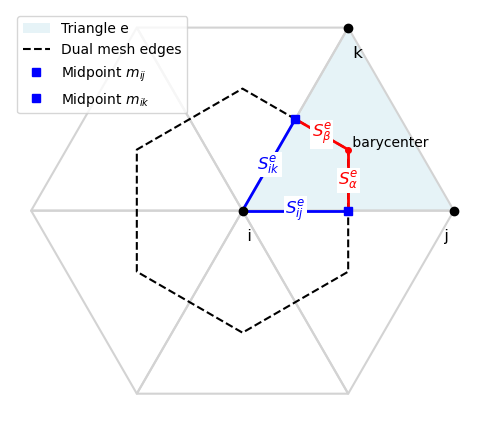

In [2]:
# Get triangle e (first triangle)
e_tri = np.array(triangles[0])
i, j, k = e_tri[0], e_tri[1], e_tri[2]
bary_e = barycenters[0]

# Compute midpoints
m_ij = midpoint(i, j)
m_ik = midpoint(i, k)

# Plotting additions
fig, ax = plt.subplots(figsize=(6,6))

# Re-plot all triangles
for idx, tri in enumerate(triangles):
    tri_pts = np.array(tri + [tri[0]])  # close the triangle
    ax.plot(tri_pts[:,0], tri_pts[:,1], 'lightgray')
    if idx == 0:
        ax.fill(tri_pts[:,0], tri_pts[:,1], 'lightblue', alpha=0.3, label='Triangle e')

# Dual mesh connections (dashed)
dual_points = []
for idx in range(6):
    tri = triangles[idx]
    bary = barycenters[idx]
    mid1 = midpoint(i, tri[1])
    mid2 = midpoint(i, tri[2])
    dual_points.append(mid1)
    dual_points.append(bary)
    dual_points.append(mid2)

dual_polygon = np.array(dual_points)
ax.plot(dual_polygon[:,0], dual_polygon[:,1], 'k--', lw=1.5, label='Dual mesh edges')

# Key segment annotations
def draw_segment(p1, p2, label, color):
    ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color=color, lw=2)
    mid = midpoint(p1, p2)
    ax.text(mid[0], mid[1], f"${label}$", fontsize=12, color=color, ha='center', va='center',
            bbox=dict(facecolor='white', edgecolor='none', pad=1))

# S^e_{ij}
draw_segment(i, m_ij, r"S^e_{ij}", "blue")

# S^e_{ik}
draw_segment(i, m_ik, r"S^e_{ik}", "blue")

# S^{\alpha}
draw_segment(bary_e, m_ij, r"S^e_{\alpha}", "red")

# S^{\beta}
draw_segment(bary_e, m_ik, r"S^e_{\beta}", "red")

# Mark key points
ax.plot(i[0], i[1], 'ko')
ax.text(i[0], i[1], '  \n i ', fontsize=12, ha='left', va='top')

ax.plot(j[0], j[1], 'ko')
ax.text(j[0], j[1], ' \n j ', fontsize=12, ha='right', va='top')

ax.plot(k[0], k[1], 'ko')
ax.text(k[0], k[1], '  \n k ', fontsize=12, ha='left', va='top')

ax.plot(bary_e[0], bary_e[1], 'ro', markersize=4)
ax.text(bary_e[0], bary_e[1], r' barycenter', fontsize=10, ha='left', va='bottom')

# Mark midpoints of triangle e's edges (only m_ij and m_ik)
ax.plot(m_ij[0], m_ij[1], 'bs', markersize=6, label='Midpoint $m_{ij}$')
ax.plot(m_ik[0], m_ik[1], 'bs', markersize=6, label='Midpoint $m_{ik}$')

# Only show legend for midpoints, not for other elements
handles, labels = ax.get_legend_handles_labels()
# Filter to only midpoint labels (avoid duplicates)
midpoint_handles = []
midpoint_labels = []
for h, l in zip(handles, labels):
    if 'Midpoint' in l and l not in midpoint_labels:
        midpoint_handles.append(h)
        midpoint_labels.append(l)
if midpoint_handles:
    ax.legend(midpoint_handles, midpoint_labels, loc='best')

# Plot style
ax.set_aspect('equal')
ax.axis('off')
# plt.title("Annotated Segments on Triangle e")
plt.legend()
plt.show()


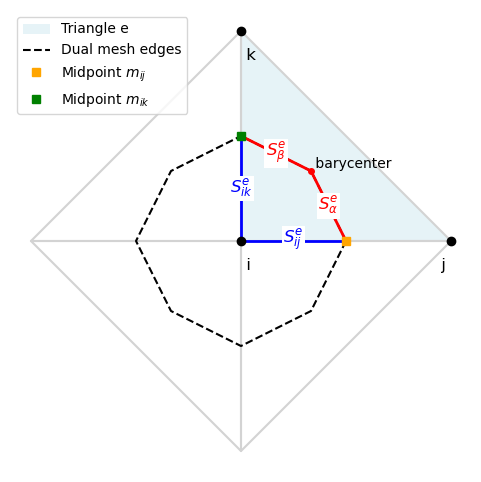

In [3]:

# Helper functions
def midpoint(p1, p2):
    return (p1 + p2) / 2

def barycenter(tri):
    return np.mean(tri, axis=0)

# Create central vertex i
center = np.array([0.0, 0.0])

# Create 4 surrounding points for right isosceles triangles (placed at 90 degree intervals)
# Each triangle will be right isosceles with legs of length 1
# Place points at (1,0), (0,1), (-1,0), (0,-1)
vertices = [np.array([1, 0]), np.array([0, 1]), np.array([-1, 0]), np.array([0, -1])]

# Create 4 right isosceles triangles around center
# Each triangle: [center, v_n, v_{n+1}]
triangles = [
    [center, vertices[n], vertices[(n + 1) % 4]] for n in range(4)
]

# Compute barycenters and midpoints
barycenters = [barycenter(np.array(tri)) for tri in triangles]
midpoints = [[midpoint(np.array(tri[0]), np.array(tri[1])),
              midpoint(np.array(tri[1]), np.array(tri[2])),
              midpoint(np.array(tri[2]), np.array(tri[0]))]
             for tri in triangles]

# Get triangle e (first triangle)
e_tri = np.array(triangles[0])
i, j, k = e_tri[0], e_tri[1], e_tri[2]
bary_e = barycenters[0]

# Compute midpoints for e
m_ij = midpoint(i, j)
m_ik = midpoint(i, k)

# Plotting
fig, ax = plt.subplots(figsize=(6,6))

# Re-plot all triangles
for idx, tri in enumerate(triangles):
    tri_pts = np.array(tri + [tri[0]])  # close the triangle
    ax.plot(tri_pts[:,0], tri_pts[:,1], 'lightgray')
    if idx == 0:
        ax.fill(tri_pts[:,0], tri_pts[:,1], 'lightblue', alpha=0.3, label='Triangle e')

# Dual mesh connections (dashed)
dual_points = []
for idx in range(4):
    tri = triangles[idx]
    bary = barycenters[idx]
    mid1 = midpoint(center, tri[1])
    mid2 = midpoint(center, tri[2])
    dual_points.append(mid1)
    dual_points.append(bary)
    dual_points.append(mid2)

dual_polygon = np.array(dual_points)
ax.plot(dual_polygon[:,0], dual_polygon[:,1], 'k--', lw=1.5, label='Dual mesh edges')

# Key segment annotations
def draw_segment(p1, p2, label, color):
    ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color=color, lw=2)
    mid = midpoint(p1, p2)
    ax.text(mid[0], mid[1], f"${label}$", fontsize=12, color=color, ha='center', va='center',
            bbox=dict(facecolor='white', edgecolor='none', pad=1))

# S^e_{ij}
draw_segment(i, m_ij, r"S^e_{ij}", "blue")

# S^e_{ik}
draw_segment(i, m_ik, r"S^e_{ik}", "blue")

# S^{\alpha}
draw_segment(bary_e, m_ij, r"S^e_{\alpha}", "red")

# S^{\beta}
draw_segment(bary_e, m_ik, r"S^e_{\beta}", "red")

# Mark key points
ax.plot(i[0], i[1], 'ko')
ax.text(i[0], i[1], '  \n i ', fontsize=12, ha='left', va='top')

ax.plot(j[0], j[1], 'ko')
ax.text(j[0], j[1], ' \n j ', fontsize=12, ha='right', va='top')

ax.plot(k[0], k[1], 'ko')
ax.text(k[0], k[1], '  \n k ', fontsize=12, ha='left', va='top')

ax.plot(bary_e[0], bary_e[1], 'ro', markersize=4)
ax.text(bary_e[0], bary_e[1], r' barycenter', fontsize=10, ha='left', va='bottom')

# Mark midpoints of triangle e's edges (only m_ij and m_ik)
ax.plot(m_ij[0], m_ij[1], 's', markersize=6, label='Midpoint $m_{ij}$', color='orange')
ax.plot(m_ik[0], m_ik[1], 's', markersize=6, label='Midpoint $m_{ik}$', color='green')

# Only show legend for midpoints, not for other elements
handles, labels = ax.get_legend_handles_labels()
# Filter to only midpoint labels (avoid duplicates)
midpoint_handles = []
midpoint_labels = []
for h, l in zip(handles, labels):
    if 'Midpoint' in l and l not in midpoint_labels:
        midpoint_handles.append(h)
        midpoint_labels.append(l)
if midpoint_handles:
    ax.legend(midpoint_handles, midpoint_labels, loc='best')

# Plot style
ax.set_aspect('equal')
ax.axis('off')
plt.legend()
plt.show()

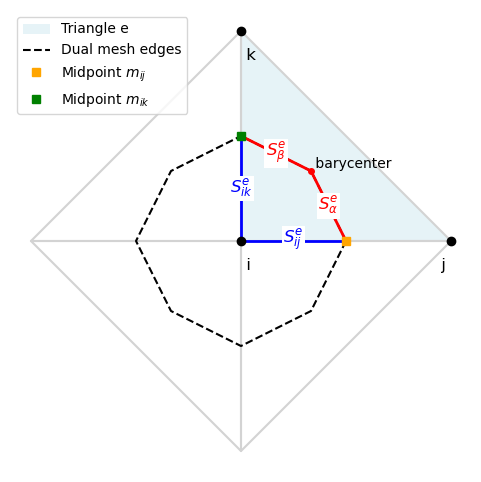

In [4]:

# Helper functions
def midpoint(p1, p2):
    return (p1 + p2) / 2

def barycenter(tri):
    return np.mean(tri, axis=0)

# Create central vertex i
center = np.array([0.0, 0.0])

# Create 4 surrounding points for right isosceles triangles (placed at 90 degree intervals)
# Each triangle will be right isosceles with legs of length 1
# Place points at (1,0), (0,1), (-1,0), (0,-1)
vertices = [np.array([1, 0]), np.array([0, 1]), np.array([-1, 0]), np.array([0, -1])]

# Create 4 right isosceles triangles around center
# Each triangle: [center, v_n, v_{n+1}]
triangles = [
    [center, vertices[n], vertices[(n + 1) % 4]] for n in range(4)
]

# Compute barycenters and midpoints
barycenters = [barycenter(np.array(tri)) for tri in triangles]
midpoints = [[midpoint(np.array(tri[0]), np.array(tri[1])),
              midpoint(np.array(tri[1]), np.array(tri[2])),
              midpoint(np.array(tri[2]), np.array(tri[0]))]
             for tri in triangles]

# Get triangle e (first triangle)
e_tri = np.array(triangles[0])
i, j, k = e_tri[0], e_tri[1], e_tri[2]
bary_e = barycenters[0]

# Compute midpoints for e
m_ij = midpoint(i, j)
m_ik = midpoint(i, k)

# Plotting
fig, ax = plt.subplots(figsize=(6,6))

# Re-plot all triangles
for idx, tri in enumerate(triangles):
    tri_pts = np.array(tri + [tri[0]])  # close the triangle
    ax.plot(tri_pts[:,0], tri_pts[:,1], 'lightgray')
    if idx == 0:
        ax.fill(tri_pts[:,0], tri_pts[:,1], 'lightblue', alpha=0.3, label='Triangle e')

# Dual mesh connections (dashed)
dual_points = []
for idx in range(4):
    tri = triangles[idx]
    bary = barycenters[idx]
    mid1 = midpoint(center, tri[1])
    mid2 = midpoint(center, tri[2])
    dual_points.append(mid1)
    dual_points.append(bary)
    dual_points.append(mid2)

dual_polygon = np.array(dual_points)
ax.plot(dual_polygon[:,0], dual_polygon[:,1], 'k--', lw=1.5, label='Dual mesh edges')

# Key segment annotations
def draw_segment(p1, p2, label, color):
    ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color=color, lw=2)
    mid = midpoint(p1, p2)
    ax.text(mid[0], mid[1], f"${label}$", fontsize=12, color=color, ha='center', va='center',
            bbox=dict(facecolor='white', edgecolor='none', pad=1))

# S^e_{ij}
draw_segment(i, m_ij, r"S^e_{ij}", "blue")

# S^e_{ik}
draw_segment(i, m_ik, r"S^e_{ik}", "blue")

# S^{\alpha}
draw_segment(bary_e, m_ij, r"S^e_{\alpha}", "red")

# S^{\beta}
draw_segment(bary_e, m_ik, r"S^e_{\beta}", "red")

# Mark key points
ax.plot(i[0], i[1], 'ko')
ax.text(i[0], i[1], '  \n i ', fontsize=12, ha='left', va='top')

ax.plot(j[0], j[1], 'ko')
ax.text(j[0], j[1], ' \n j ', fontsize=12, ha='right', va='top')

ax.plot(k[0], k[1], 'ko')
ax.text(k[0], k[1], '  \n k ', fontsize=12, ha='left', va='top')

ax.plot(bary_e[0], bary_e[1], 'ro', markersize=4)
ax.text(bary_e[0], bary_e[1], r' barycenter', fontsize=10, ha='left', va='bottom')

# Mark midpoints of triangle e's edges (only m_ij and m_ik)
ax.plot(m_ij[0], m_ij[1], 's', markersize=6, label='Midpoint $m_{ij}$', color='orange')
ax.plot(m_ik[0], m_ik[1], 's', markersize=6, label='Midpoint $m_{ik}$', color='green')

# Only show legend for midpoints, not for other elements
handles, labels = ax.get_legend_handles_labels()
# Filter to only midpoint labels (avoid duplicates)
midpoint_handles = []
midpoint_labels = []
for h, l in zip(handles, labels):
    if 'Midpoint' in l and l not in midpoint_labels:
        midpoint_handles.append(h)
        midpoint_labels.append(l)
if midpoint_handles:
    ax.legend(midpoint_handles, midpoint_labels, loc='best')

# Plot style
ax.set_aspect('equal')
ax.axis('off')
plt.legend()
plt.show()

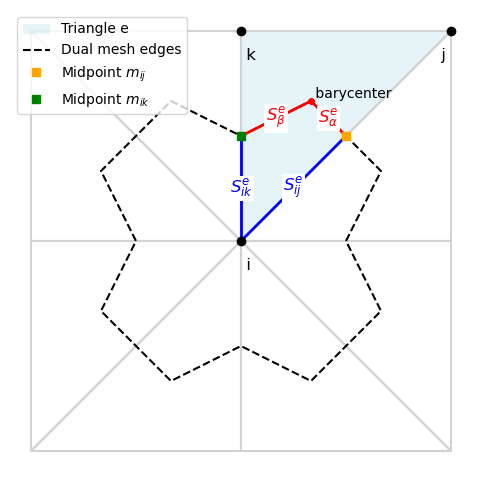

In [5]:
# Helper functions (already defined in previous cells)
# midpoint(p1, p2)
# barycenter(tri)

center = np.array([0.0, 0.0])
# Build 8 isosceles right triangles that together form a square centered at the origin.
# Each triangle has its right angle at the center, and the hypotenuse forms the outer square.

# The outer square will have its corners at (±1, ±1)
# The 8 triangles are formed by splitting each quadrant into two triangles along the diagonals

# Vertices of the outer square (counterclockwise)
square_vertices = [
    np.array([1, 1]),
    np.array([-1, 1]),
    np.array([-1, -1]),
    np.array([1, -1])
]

# For each edge of the square, split into two triangles from the center
triangles = []
for idx in range(4):
    v1 = square_vertices[idx]
    v2 = square_vertices[(idx + 1) % 4]
    # Triangle 1: center, v1, midpoint(v1, v2)
    m = midpoint(v1, v2)
    triangles.append([center, v1, m])
    # Triangle 2: center, midpoint(v1, v2), v2
    triangles.append([center, m, v2])

# Compute barycenters and midpoints
barycenters = [barycenter(np.array(tri)) for tri in triangles]
midpoints = [[midpoint(np.array(tri[0]), np.array(tri[1])),
              midpoint(np.array(tri[1]), np.array(tri[2])),
              midpoint(np.array(tri[2]), np.array(tri[0]))]
             for tri in triangles]

# Get triangle e (first triangle)
e_tri = np.array(triangles[0])
i, j, k = e_tri[0], e_tri[1], e_tri[2]
bary_e = barycenters[0]

# Compute midpoints for e
m_ij = midpoint(i, j)
m_ik = midpoint(i, k)

# Plotting
fig, ax = plt.subplots(figsize=(6,6))

# Re-plot all triangles
for idx, tri in enumerate(triangles):
    tri_pts = np.array(tri + [tri[0]])  # close the triangle
    ax.plot(tri_pts[:,0], tri_pts[:,1], 'lightgray')
    if idx == 0:
        ax.fill(tri_pts[:,0], tri_pts[:,1], 'lightblue', alpha=0.3, label='Triangle e')

# Dual mesh connections (dashed)
dual_points = []
for idx in range(8):
    tri = triangles[idx]
    bary = barycenters[idx]
    mid1 = midpoint(center, tri[1])
    mid2 = midpoint(center, tri[2])
    dual_points.append(mid1)
    dual_points.append(bary)
    dual_points.append(mid2)

dual_polygon = np.array(dual_points)
ax.plot(dual_polygon[:,0], dual_polygon[:,1], 'k--', lw=1.5, label='Dual mesh edges')

# Key segment annotations
def draw_segment(p1, p2, label, color):
    ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color=color, lw=2)
    mid = midpoint(p1, p2)
    ax.text(mid[0], mid[1], f"${label}$", fontsize=12, color=color, ha='center', va='center',
            bbox=dict(facecolor='white', edgecolor='none', pad=1))

# S^e_{ij}
draw_segment(i, m_ij, r"S^e_{ij}", "blue")

# S^e_{ik}
draw_segment(i, m_ik, r"S^e_{ik}", "blue")

# S^{\alpha}
draw_segment(bary_e, m_ij, r"S^e_{\alpha}", "red")

# S^{\beta}
draw_segment(bary_e, m_ik, r"S^e_{\beta}", "red")

# Mark key points
ax.plot(i[0], i[1], 'ko')
ax.text(i[0], i[1], '  \n i ', fontsize=12, ha='left', va='top')

ax.plot(j[0], j[1], 'ko')
ax.text(j[0], j[1], ' \n j ', fontsize=12, ha='right', va='top')

ax.plot(k[0], k[1], 'ko')
ax.text(k[0], k[1], '  \n k ', fontsize=12, ha='left', va='top')

ax.plot(bary_e[0], bary_e[1], 'ro', markersize=4)
ax.text(bary_e[0], bary_e[1], r' barycenter', fontsize=10, ha='left', va='bottom')

# Mark midpoints of triangle e's edges (only m_ij and m_ik)
ax.plot(m_ij[0], m_ij[1], 's', markersize=6, label='Midpoint $m_{ij}$', color='orange')
ax.plot(m_ik[0], m_ik[1], 's', markersize=6, label='Midpoint $m_{ik}$', color='green')

# Only show legend for midpoints, not for other elements
handles, labels = ax.get_legend_handles_labels()
midpoint_handles = []
midpoint_labels = []
for h, l in zip(handles, labels):
    if 'Midpoint' in l and l not in midpoint_labels:
        midpoint_handles.append(h)
        midpoint_labels.append(l)
if midpoint_handles:
    ax.legend(midpoint_handles, midpoint_labels, loc='best')

# Plot style
ax.set_aspect('equal')
ax.axis('off')
plt.legend()
plt.show()

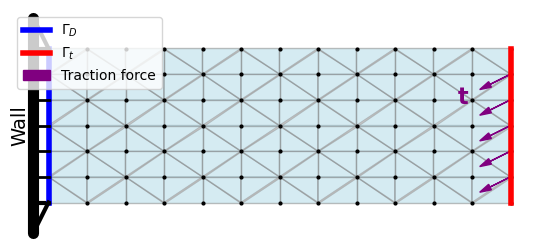

In [6]:
def make_beam_mesh(width, height, shape):
    x0 = -width/2.0
    y0 = -height/2.0
    I  = shape[0]
    J  = shape[1]
    dx = width/float(I)
    dy = height/float(J)
    V = np.zeros(((I+1)*(J+1),2),dtype=np.float64)
    for j in range(J+1):
        for i in range(I+1):
            k = i + j*(I+1)
            V[k,0] = x0 + i*dx
            V[k,1] = y0 + j*dy
    T = np.zeros((2*I*J,3),dtype=np.int32)
    for j in range(J):
        for i in range(I):
            k00 = (i  ) + (j  )*(I+1)
            k01 = (i+1) + (j  )*(I+1)
            k10 = (i  ) + (j+1)*(I+1)
            k11 = (i+1) + (j+1)*(I+1)
            e = 2*(i + j*I)
            if (i+j)%2:
                T[e,  :] = (k00,k01,k11)
                T[e+1,:] = (k00,k11,k10)
            else:
                T[e,  :] = (k10,k00,k01)
                T[e+1,:] = (k10,k01,k11)                    
    return V, T

V, T = make_beam_mesh(6.0,2.0,(12,6))

fig, ax = plt.subplots(figsize=(8, 3))

# Define boundary variables from mesh V
x_wall = V[:,0].min()
x_right = V[:,0].max()
ymin = V[:,1].min()
ymax = V[:,1].max()
wall_pad = 0.4

# Plot triangles
for t in T:
    pts = V[t]
    tri = plt.Polygon(pts, edgecolor='gray', facecolor='lightblue', alpha=0.5)
    ax.add_patch(tri)

# Plot mesh nodes
ax.plot(V[:,0], V[:,1], 'ko', markersize=2)

# Draw the wall at the left boundary (vertical line at min x)
ax.plot([x_wall-0.2, x_wall], [ymin, ymin], color='k', lw=3)
ax.plot([x_wall-0.2, x_wall], [ymax, ymax], color='k', lw=3)
ax.plot([x_wall-0.2, x_wall-0.2], [ymin, ymax], color='k', lw=6)
# Color the leftmost (wall) edge blue and add to legend only
ax.plot([x_wall, x_wall], [ymin, ymax], color='blue', lw=4, label=r'$\Gamma_D$')
# Mark the wall with a text label
ax.text(x_wall-0.25, (ymin+ymax)/2, "Wall", fontsize=14, rotation=90, va='center', ha='right', color='black')

# Color the rightmost edge red and add to legend only
ax.plot([x_right, x_right], [ymin, ymax], color='red', lw=4, label=r'$\Gamma_t$')
# ax.text(x_right+0.15, (ymin+ymax)/2, r"$\Gamma_t$", fontsize=16, rotation=90, va='center', ha='left', color='red')

# Draw the wall higher than the mesh and make it look "glued"
ax.plot([x_wall-0.2, x_wall], [ymin-wall_pad, ymin], color='k', lw=3)
ax.plot([x_wall-0.2, x_wall], [ymax+wall_pad, ymax], color='k', lw=3)
ax.plot([x_wall-0.2, x_wall-0.2], [ymin-wall_pad, ymax+wall_pad], color='k', lw=8, solid_capstyle='round')
# "Glue" effect: draw short horizontal lines connecting wall to mesh at several mesh nodes
for y in np.linspace(ymin, ymax, 7):
    ax.plot([x_wall-0.2, x_wall], [y, y], color='k', lw=2)

# Add traction vector force on the right boundary (diagonal, downward and left)
traction_color = 'purple'
traction_dx = -0.4
traction_dy = -0.2  # negative for downward
right_nodes = np.where(np.isclose(V[:,0], x_right))[0]
for idx in right_nodes[1:-1]:
    ax.arrow(V[idx,0], V[idx,1], traction_dx, traction_dy, head_width=0.08, head_length=0.15, fc=traction_color, ec=traction_color, length_includes_head=True)
# Add label $\mathbf{t}$ to one of the arrows
ax.text(V[right_nodes[-2],0]+traction_dx - 0.3, V[right_nodes[-2],1]+traction_dy/2-0.05, r"$\mathbf{t}$", fontsize=16, color=traction_color, ha='left', va='top')

# Add a legend handle for the traction vector
import matplotlib.patches as mpatches
traction_patch = mpatches.FancyArrowPatch((0,0), (traction_dx, traction_dy), color=traction_color, mutation_scale=15, label=r'Traction force')
handles, labels = ax.get_legend_handles_labels()
handles.append(traction_patch)
labels.append(r'Traction force')

ax.set_aspect('equal')
ax.set_xlim(x_wall-0.5, x_right+0.5)
ax.set_ylim(ymin-wall_pad-0.1, ymax+wall_pad+0.1)
ax.axis('off')
ax.legend(handles, labels, loc='upper left')
# plt.title("Beam Mesh with $\Gamma_D$ (wall), $\Gamma_t$ (traction), and traction $\\mathbf{t}$")
plt.show()
